
## 1. Environment Setup and Dataset Preparation

### Objective

The first step is to configure the Python environment, initialize the required deep learning libraries, and load the CIFAR-10 dataset.

### Dataset

CIFAR-10 contains 60,000 RGB images distributed across 10 classes. Each image has a resolution of 32 × 32 pixels and three color channels.

The dataset is divided into:
- 50,000 training images
- 10,000 test images

We use this dataset to simulate images captured by a UAV. The classification task represents the ground station's ability to recognize objects after receiving compressed semantic information over a wireless channel.

### Implementation

We use PyTorch for neural network training and TorchVision for dataset loading and preprocessing.

The images are converted into tensors with pixel values normalized to the range [0, 1]. We also establish a random seed for reproducibility and configure GPU acceleration when available.

DataLoaders organize images into batches for efficient training and evaluation.

### Expected Outcome

Successful execution should confirm the selected computing device, dataset size, image dimensions, and available CIFAR-10 classes.


In [2]:
#Environment Setup and CIFAR-10 Dataset


import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

transform = transforms.ToTensor()


train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2
)


images, labels = next(iter(train_loader))

print("\nDataset Information:")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)


Device: cuda

Dataset Information:
Training samples: 50000
Testing samples: 10000
Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



## 2. CNN-Based Semantic Encoder

### Objective

The objective of the semantic encoder is to transform a full-resolution input image into a compact latent representation containing task-relevant information.

In the proposed UAV communication system, the encoder is located onboard the UAV. Instead of transmitting all image pixels, the UAV extracts semantic features that help the ground station recognize the objects present in the image.

### Encoder Architecture

We implement a convolutional neural network (CNN) consisting of three convolutional blocks followed by a fully connected projection layer.

Each convolutional block includes:

- A convolutional layer for learning image features.
- Batch normalization for stabilizing training.
- A ReLU activation function for introducing nonlinearity.
- Max pooling for reducing spatial dimensions.

The image dimensions change as follows:

1. Input: 3 × 32 × 32
2. First convolutional block: 64 × 16 × 16
3. Second convolutional block: 128 × 8 × 8
4. Third convolutional block: 256 × 4 × 4
5. Flattened representation: 4096 features
6. Final latent representation: 256 features

### Semantic Compression

Each CIFAR-10 image originally contains:

3 × 32 × 32 = 3072 pixel values.

The encoder produces 256 real-valued latent features, giving a nominal representation ratio of:

256 / 3072 = 1/12

This corresponds to a 12× reduction in the number of scalar values transmitted, although it does not directly represent a 12× reduction in bit rate.

### Expected Outcome

The encoder should accept an input batch with dimensions:

[128, 3, 32, 32]

and produce a latent representation with dimensions:

[128, 256]

The resulting latent vectors will later undergo power normalization and transmission through a simulated AWGN channel.


In [3]:
#CNN Semantic Encoder


class SemanticEncoder(nn.Module):
    def __init__(self, latent_dim=256):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1: 3x32x32 -> 64x16x16
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 64x16x16 -> 128x8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 128x8x8 -> 256x4x4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Flatten and project to latent dimension
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, latent_dim)
        )

    def forward(self, x):
        return self.features(x)

encoder = SemanticEncoder(latent_dim=256).to(device)

sample_images = images.to(device)

with torch.no_grad():
    latent_features = encoder(sample_images)

print("Original image shape:", sample_images.shape)
print("Encoded latent shape:", latent_features.shape)
print("Original values per image:", 3 * 32 * 32)
print("Latent features per image:", latent_features.shape[1])
print("Representation ratio:", (3 * 32 * 32) / latent_features.shape[1])

assert latent_features.shape == (128, 256)

print("\npassed")


Original image shape: torch.Size([128, 3, 32, 32])
Encoded latent shape: torch.Size([128, 256])
Original values per image: 3072
Latent features per image: 256
Representation ratio: 12.0

CNN Semantic Encoder verification passed!



## 3. Power Normalization and AWGN Wireless Channel

### Objective

The objective of this section is to simulate the transmission of encoded semantic features from the UAV to the ground station over a noisy wireless communication channel.

After extracting semantic features using the CNN encoder, the UAV must transmit the resulting latent representation while satisfying a transmission power constraint.

We implement two operations:

1. Power normalization of the transmitted semantic features.
2. Additive White Gaussian Noise (AWGN) channel simulation.

### Power Normalization

The encoder produces a latent vector containing 256 real-valued features. Before transmission, we normalize this vector to ensure consistent average transmission power across different images.

For a latent vector z with k elements, the normalized representation is:

z_norm = sqrt(k) * z / ||z||_2

This ensures that the average transmitted power per real-valued symbol is approximately one (exactly one for each nonzero vector, up to numerical precision).

### AWGN Channel Model

The received representation is modeled as:

y = z_norm + n

where:

- z_norm represents the normalized transmitted semantic features.
- n represents additive Gaussian noise.
- y represents the noisy semantic features received by the ground station.

The Gaussian noise has zero mean and variance determined by the signal-to-noise ratio (SNR).

SNR is expressed in decibels:

SNR_dB = 10 log10(P_signal / P_noise)

With normalized signal power equal to one, the noise standard deviation is:

sigma = sqrt(1 / 10^(SNR_dB / 10))

### SNR Conditions

We will evaluate the model at several SNR levels:

- 0 dB: High noise
- 5 dB: Moderate-to-high noise
- 10 dB: Moderate noise
- 15 dB: Lower noise
- 20 dB: Low noise

A higher SNR corresponds to a cleaner wireless channel.

### Differentiable Channel

The AWGN channel is implemented in PyTorch so that gradients can propagate through the channel during neural network training.

This enables the semantic encoder and receiver classifier to be trained jointly under simulated wireless noise.

### Expected Outcome

The AWGN channel should preserve the dimensions of the encoded latent representation while introducing noise according to the specified SNR.

For an input latent tensor of shape [128, 256], the channel output should also have shape [128, 256].

We will verify the output dimensions, transmitted signal power, and measured noise power for different SNR conditions.


In [4]:
# Power Normalization and AWGN Channel

class AWGNChannel(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, z, snr_db):

        # Each nonzero latent vector has average symbol power 1
        k = z.shape[1]

        z_normalized = F.normalize(
            z, p=2, dim=1, eps=1e-12
        ) * (k ** 0.5)

        snr_linear = 10 ** (snr_db / 10)

        noise_std = (1.0 / snr_linear) ** 0.5

        noise = torch.randn_like(z_normalized) * noise_std

        received = z_normalized + noise

        return received

channel = AWGNChannel().to(device)

# Use features from the previously implemented CNN encoder
encoder.eval()

with torch.no_grad():
    z = encoder(sample_images)

    # Normalize separately for verification
    z_normalized = F.normalize(
        z, p=2, dim=1, eps=1e-12
    ) * (z.shape[1] ** 0.5)

    signal_power = z_normalized.pow(2).mean().item()

    print("Original latent shape:", z.shape)
    print("Normalized signal power:", round(signal_power, 4))

    for snr in [0, 5, 10, 15, 20]:

        received = channel(z, snr_db=snr)

        noise = received - z_normalized

        noise_power = noise.pow(2).mean().item()

        measured_snr = 10 * np.log10(
            signal_power / noise_power
        )

        print(
            f"SNR Target: {snr:2d} dB | "
            f"Measured SNR: {measured_snr:6.2f} dB | "
            f"Output Shape: {tuple(received.shape)}"
        )

        assert received.shape == z.shape
        assert torch.isfinite(received).all()

print("\npassed")


Original latent shape: torch.Size([128, 256])
Normalized signal power: 1.0
SNR Target:  0 dB | Measured SNR:   0.04 dB | Output Shape: (128, 256)
SNR Target:  5 dB | Measured SNR:   4.92 dB | Output Shape: (128, 256)
SNR Target: 10 dB | Measured SNR:  10.00 dB | Output Shape: (128, 256)
SNR Target: 15 dB | Measured SNR:  14.97 dB | Output Shape: (128, 256)
SNR Target: 20 dB | Measured SNR:  20.02 dB | Output Shape: (128, 256)

passed



## 4. Ground Station Classification Receiver

### Objective

The objective of the classification receiver is to recover task-relevant information from semantic features transmitted over the noisy wireless channel.

In our UAV search-and-rescue system, the ground station receives a latent representation generated by the UAV's CNN encoder. Because wireless transmission introduces noise, the received features may differ from those originally transmitted.

Rather than reconstructing the entire image before performing classification, we directly classify the received semantic features.

This task-oriented approach prioritizes accurate object recognition while reducing the amount of transmitted information.

### Receiver Architecture

We implement a fully connected neural network that maps the 256-dimensional received latent representation to the 10 CIFAR-10 classes.

The receiver contains:

1. An input layer accepting 256 noisy semantic features.
2. A fully connected hidden layer containing 256 neurons.
3. A ReLU activation function.
4. A dropout layer with a probability of 0.25.
5. An output layer producing 10 classification logits.

### Classification and Confidence

The receiver produces 10 logits, each corresponding to a CIFAR-10 class.

During evaluation, the logits are converted into class probabilities using the softmax function:

p_i = exp(logit_i) / sum_j exp(logit_j)

The predicted class is the class with the highest probability.

The maximum predicted probability is also recorded as a confidence score, which may later support adaptive retransmission and verification decisions.

However, softmax confidence is not necessarily a calibrated estimate of correctness.

### Training Objective

The classifier will be trained using cross-entropy loss:

L_classification = CrossEntropy(logits, true_labels)

During end-to-end training, gradients from the classification loss will propagate through the classifier, AWGN channel, and CNN encoder.

This allows the encoder to learn semantic representations optimized for classification under wireless noise.

### Expected Outcome

Given a received tensor of shape:

[128, 256]

the classifier should output:

[128, 10]

Each row contains the classification logits for one image.

After applying softmax, the resulting probabilities should sum to approximately one for each image.

At this stage, the network weights are randomly initialized. Meaningful classification accuracy will only be obtained after training.


In [6]:
#Ground Station Classification Receiver

class SemanticClassifier(nn.Module):
    def __init__(self, latent_dim=256, num_classes=10):
        super().__init__()

        self.layers = nn.Sequential(

            # Hidden fully connected layer
            nn.Linear(latent_dim, 256),

            # Nonlinear activation
            nn.ReLU(),

            # Regularization to reduce overfitting
            nn.Dropout(p=0.25),

            # Output classification logits
            nn.Linear(256, num_classes)
        )

    def forward(self, received):
        return self.layers(received)


classifier = SemanticClassifier(
    latent_dim=256,
    num_classes=10
).to(device)

encoder.eval()
classifier.eval()

with torch.no_grad():

    # Encode original CIFAR-10 images
    z = encoder(sample_images)

    # Transmit features through AWGN at 10 dB
    received = channel(z, snr_db=10.0)

    # Classify received features
    logits = classifier(received)

    # Convert logits to probabilities
    probabilities = F.softmax(logits, dim=1)

    # Obtain predicted class and confidence
    confidence, predicted_classes = torch.max(
        probabilities, dim=1
    )


print("Received feature shape:", received.shape)
print("Classification logits shape:", logits.shape)
print("Probability tensor shape:", probabilities.shape)

print("\nFirst 5 predictions:")

for i in range(5):

    predicted_label = train_dataset.classes[
        predicted_classes[i].item()
    ]

    true_label = train_dataset.classes[
        labels[i].item()
    ]

    print(
        f"Image {i+1}: "
        f"Predicted = {predicted_label:10s} | "
        f"True = {true_label:10s} | "
        f"Confidence = {confidence[i].item():.4f}"
    )

assert logits.shape == (128, 10)
assert probabilities.shape == (128, 10)

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(128, device=device),
    atol=1e-5
)

assert torch.isfinite(logits).all()

print("\npassed")


Received feature shape: torch.Size([128, 256])
Classification logits shape: torch.Size([128, 10])
Probability tensor shape: torch.Size([128, 10])

First 5 predictions:
Image 1: Predicted = airplane   | True = frog       | Confidence = 0.1476
Image 2: Predicted = ship       | True = airplane   | Confidence = 0.1339
Image 3: Predicted = airplane   | True = deer       | Confidence = 0.1227
Image 4: Predicted = ship       | True = automobile | Confidence = 0.1195
Image 5: Predicted = airplane   | True = bird       | Confidence = 0.1421

passed



## 5. End-to-End Semantic Communication System

### Objective

The objective of this section is to integrate the previously implemented semantic encoder, AWGN wireless channel, and classification receiver into a unified neural network architecture.

The system models a UAV transmitting compact semantic information to a ground station for image classification.

### End-to-End Architecture

The system consists of three main components:

**1. UAV Semantic Encoder**

A convolutional neural network extracts a 256-dimensional latent representation from each CIFAR-10 image.

**2. Wireless Communication Channel**

The latent representation is power-normalized and transmitted through a differentiable AWGN channel. The channel introduces Gaussian noise based on a specified signal-to-noise ratio (SNR).

**3. Ground Station Classification Receiver**

A fully connected neural network processes the received noisy semantic features and outputs classification logits for the 10 CIFAR-10 classes.

The complete communication pipeline is:

CIFAR-10 Image → CNN Encoder → Power Normalization → AWGN Channel → Classification Receiver → Predicted Class

### Joint Optimization

Instead of training the encoder and classifier independently, we optimize them jointly using the classification cross-entropy loss.

The overall classification objective is:

L_class = CrossEntropy(f_receiver(Channel(f_encoder(x))), y)

where:

- x is the input image.
- y is the ground-truth class label.
- f_encoder is the CNN semantic encoder.
- Channel represents power normalization and AWGN transmission.
- f_receiver is the ground-station classification network.

Because the AWGN channel is differentiable with respect to its input, gradients from the classification loss can propagate through the receiver and channel to the encoder.

This enables the encoder to learn features that remain useful for classification after noisy wireless transmission.

### Initial Configuration

For the first prototype, we use:

- Dataset: CIFAR-10
- Input dimensions: 3 × 32 × 32
- Latent dimension: 256 real-valued channel symbols
- Channel model: AWGN
- Initial test SNR: 10 dB
- Classification classes: 10
- Optimization objective: Cross-entropy loss

The model will later be extended to support 512-symbol transmission, multiple SNR conditions, generative reconstruction, and adaptive rate selection.

### Expected Outcome

The integrated model should accept an input image batch of shape [128, 3, 32, 32] and output classification logits of shape [128, 10].

We will also verify that a backward pass produces valid gradients in both the encoder and classifier.

Successful execution confirms that the complete neural communication pipeline is structurally functional and ready for training.


In [8]:
# End-to-End Semantic Communication System

class SemanticCommSystem(nn.Module):
    def __init__(self, latent_dim=256, num_classes=10):
        super().__init__()

        # UAV transmitter: semantic feature extraction
        self.encoder = SemanticEncoder(
            latent_dim=latent_dim
        )

        # Wireless communication channel
        self.channel = AWGNChannel()

        # Ground station: classification receiver
        self.classifier = SemanticClassifier(
            latent_dim=latent_dim,
            num_classes=num_classes
        )

    def forward(self, images, snr_db):

        # Step 1: Extract semantic features
        latent_features = self.encoder(images)

        # Step 2: Transmit over AWGN channel
        received_features = self.channel(
            latent_features,
            snr_db=snr_db
        )

        # Step 3: Classify received features
        logits = self.classifier(received_features)

        return logits

model = SemanticCommSystem(
    latent_dim=256,
    num_classes=10
).to(device)

print("Model initialized successfully.")

sample_images = images.to(device)
sample_labels = labels.to(device)

model.train()

snr_db = 10.0

logits = model(
    sample_images,
    snr_db=snr_db
)

criterion = nn.CrossEntropyLoss()

loss = criterion(logits, sample_labels)

print("\nForward Pass Results:")
print("Input shape:", sample_images.shape)
print("Output logits shape:", logits.shape)
print("Classification loss:", round(loss.item(), 4))


model.zero_grad(set_to_none=True)

loss.backward()

encoder_grad = model.encoder.features[0].weight.grad
classifier_grad = model.classifier.layers[0].weight.grad

assert encoder_grad is not None
assert classifier_grad is not None

assert torch.isfinite(encoder_grad).all()
assert torch.isfinite(classifier_grad).all()

print("\nGradient Verification:")
print(
    "Encoder gradient norm:",
    round(encoder_grad.norm().item(), 6)
)
print(
    "Classifier gradient norm:",
    round(classifier_grad.norm().item(), 6)
)

assert logits.shape == (sample_images.shape[0], 10)
assert torch.isfinite(loss).item()
assert encoder_grad.norm().item() > 0
assert classifier_grad.norm().item() > 0

print("\npassed")


Model initialized successfully.

Forward Pass Results:
Input shape: torch.Size([128, 3, 32, 32])
Output logits shape: torch.Size([128, 10])
Classification loss: 2.3495

Gradient Verification:
Encoder gradient norm: 0.280328
Classifier gradient norm: 0.724455

passed



## 6. Training Configuration and Validation Dataset

### Objective

The objective of this section is to prepare the end-to-end semantic communication model for supervised training.

Our system must learn to extract compact semantic features that remain useful for image classification after transmission through a noisy wireless channel.

We configure the training and validation datasets, classification loss function, optimizer, and channel conditions used during training.

### Training and Validation Split

The original CIFAR-10 training dataset contains 50,000 images.

We divide these images into:

- Training set: 45,000 images (90%)
- Validation set: 5,000 images (10%)

The training set is used to update the neural network parameters, while the validation set is used to evaluate generalization and select the best model.

The separate CIFAR-10 test set containing 10,000 images will be reserved for final evaluation.

### SNR-Aware Training

Because the semantic representations will be transmitted through a noisy wireless channel, the model must learn to operate under multiple channel conditions.

Rather than training only at one fixed SNR, we randomly sample the training SNR between 0 and 20 dB.

This exposes the encoder and classifier to different noise levels and encourages robustness across channel conditions.

During validation, we initially use a fixed SNR of 10 dB to compare model performance consistently between epochs.

Later experiments will evaluate classification accuracy across the full SNR range.

### Classification Loss

We use cross-entropy loss to measure the difference between the predicted class logits and the ground-truth CIFAR-10 labels.

The classification objective is:

L_class = CrossEntropy(predicted_logits, true_labels)

Because our AWGN channel is differentiable with respect to the transmitted semantic features, the classification loss can be used to train both the UAV encoder and ground-station receiver jointly.

### Optimization Configuration

We use the Adam optimizer with the following initial settings:

- Learning rate: 0.001
- Batch size: 128 for training
- Validation batch size: 256
- Training epochs: 15
- Training SNR range: 0–20 dB
- Validation SNR: 10 dB
- Latent dimension: 256 real-valued symbols

These settings provide an initial training configuration and may be adjusted based on observed convergence and validation performance.

### Expected Outcome

This cell should prepare the training and validation DataLoaders, initialize the optimizer and loss function, and display the training configuration.

No model training occurs in this cell. The next section will implement the full training and validation loop.


In [9]:

# ============================================================
# ECE 527 Project 5
# Cell 6: Training Configuration and Validation Split
# ============================================================

from torch.utils.data import random_split

# ------------------------------------------------------------
# 1. Split CIFAR-10 Training Dataset
# ------------------------------------------------------------

train_size = 45000
val_size = 5000

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

# ------------------------------------------------------------
# 2. Create Training and Validation DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_subset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_subset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------------------
# 3. Define Training Hyperparameters
# ------------------------------------------------------------

LATENT_DIM = 256
NUM_CLASSES = 10

LEARNING_RATE = 0.001
NUM_EPOCHS = 15

TRAIN_SNR_MIN = 0.0
TRAIN_SNR_MAX = 20.0

VAL_SNR = 10.0

# ------------------------------------------------------------
# 4. Initialize Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# 5. Initialize Optimizer
# ------------------------------------------------------------

# Reuse the integrated model created in Cell 5
model = model.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# ------------------------------------------------------------
# 6. Verify Training Configuration
# ------------------------------------------------------------

print("Training Configuration")
print("-" * 45)

print("Device:", device)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

print("\nModel Configuration:")
print("Latent dimension:", LATENT_DIM)
print("Number of classes:", NUM_CLASSES)

print("\nOptimization:")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Training epochs:", NUM_EPOCHS)

print("\nChannel Conditions:")
print(
    f"Training SNR: {TRAIN_SNR_MIN:.0f}"
    f" to {TRAIN_SNR_MAX:.0f} dB"
)
print(f"Validation SNR: {VAL_SNR:.0f} dB")

# ------------------------------------------------------------
# 7. Verify Dataset Split
# ------------------------------------------------------------

assert len(train_subset) == 45000
assert len(val_subset) == 5000
assert len(test_dataset) == 10000

print("\nTraining configuration verified successfully!")


Training Configuration
---------------------------------------------
Device: cuda
Training samples: 45000
Validation samples: 5000
Test samples: 10000

Model Configuration:
Latent dimension: 256
Number of classes: 10

Optimization:
Optimizer: Adam
Learning rate: 0.001
Training epochs: 15

Channel Conditions:
Training SNR: 0 to 20 dB
Validation SNR: 10 dB

Training configuration verified successfully!



## 7. End-to-End Training and Validation

### Objective

The objective of this section is to jointly train the CNN semantic encoder and ground-station classification receiver under simulated wireless channel conditions.

The semantic encoder must learn to extract compact representations containing sufficient task-relevant information for accurate image classification, even after the transmitted features are corrupted by channel noise.

### Training Procedure

For each training epoch:

1. Load a batch of CIFAR-10 images and their class labels.
2. Randomly select an SNR between 0 and 20 dB.
3. Encode the input images into 256-dimensional semantic representations.
4. Normalize and transmit these features through the AWGN channel.
5. Classify the received noisy representations.
6. Calculate classification cross-entropy loss.
7. Backpropagate the loss through the classifier, channel, and encoder.
8. Update the trainable model parameters using the Adam optimizer.

The SNR is randomly sampled for each batch to expose the system to different channel conditions during training.

### Validation Procedure

At the end of each training epoch, we evaluate the model on the separate CIFAR-10 validation dataset.

Validation is performed at a fixed SNR of 10 dB to provide a consistent reference condition.

We record:

- Average training cross-entropy loss.
- Training classification accuracy.
- Average validation cross-entropy loss.
- Validation classification accuracy.

Because AWGN introduces random noise, validation results may vary slightly even when the model parameters remain unchanged.

### Model Selection and Checkpointing

The model with the highest validation accuracy is saved as the best checkpoint.

This checkpoint will be used in subsequent experiments to evaluate classification performance across different SNR conditions.

We also save training history to support learning-curve visualization and experimental analysis.

### Expected Outcome

After 15 training epochs, we expect the classification loss to decrease and the classification accuracy to improve relative to the randomly initialized model.

The exact accuracy depends on network capacity, optimization settings, and the robustness of the learned semantic representations.

This experiment establishes the first trained non-generative semantic communication baseline for our project.


In [10]:

# ============================================================
# ECE 527 Project 5
# Cell 7: End-to-End Training and Validation
# ============================================================

import os
import copy
import time

# ------------------------------------------------------------
# 1. Create Directory for Model Checkpoints
# ------------------------------------------------------------

os.makedirs("checkpoints", exist_ok=True)

BEST_MODEL_PATH = "checkpoints/best_semantic_model_256.pth"

# ------------------------------------------------------------
# 2. Initialize Training History
# ------------------------------------------------------------

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_epoch = 0

# ------------------------------------------------------------
# 3. Training Loop
# ------------------------------------------------------------

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model.train()

    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for batch_images, batch_labels in train_loader:

        batch_images = batch_images.to(
            device, non_blocking=True
        )

        batch_labels = batch_labels.to(
            device, non_blocking=True
        )

        # Randomly sample channel SNR for this batch
        snr_db = np.random.uniform(
            TRAIN_SNR_MIN,
            TRAIN_SNR_MAX
        )

        # Reset gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass through encoder, channel, classifier
        logits = model(batch_images, snr_db=snr_db)

        # Classification loss
        loss = criterion(logits, batch_labels)

        # Backpropagation
        loss.backward()

        # Update encoder and classifier parameters
        optimizer.step()

        # Accumulate training statistics
        running_loss += loss.item() * batch_images.size(0)

        predictions = logits.argmax(dim=1)

        correct_train += (
            predictions == batch_labels
        ).sum().item()

        total_train += batch_labels.size(0)

    train_loss = running_loss / total_train
    train_accuracy = 100.0 * correct_train / total_train

    # --------------------------------------------------------
    # 4. Validation Loop at Fixed 10 dB SNR
    # --------------------------------------------------------

    model.eval()

    val_running_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():

        for batch_images, batch_labels in val_loader:

            batch_images = batch_images.to(
                device, non_blocking=True
            )

            batch_labels = batch_labels.to(
                device, non_blocking=True
            )

            logits = model(
                batch_images,
                snr_db=VAL_SNR
            )

            loss = criterion(logits, batch_labels)

            val_running_loss += (
                loss.item() * batch_images.size(0)
            )

            predictions = logits.argmax(dim=1)

            correct_val += (
                predictions == batch_labels
            ).sum().item()

            total_val += batch_labels.size(0)

    val_loss = val_running_loss / total_val
    val_accuracy = 100.0 * correct_val / total_val

    # --------------------------------------------------------
    # 5. Store Training History
    # --------------------------------------------------------

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # --------------------------------------------------------
    # 6. Save Best Model
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": best_val_accuracy,
                "latent_dim": LATENT_DIM,
                "validation_snr_db": VAL_SNR
            },
            BEST_MODEL_PATH
        )

    # --------------------------------------------------------
    # 7. Display Epoch Results
    # --------------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

# ------------------------------------------------------------
# 8. Training Summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING COMPLETED")
print("=" * 55)

print("Best validation accuracy:", f"{best_val_accuracy:.2f}%")
print("Best epoch:", best_epoch)
print("Best model checkpoint:", BEST_MODEL_PATH)

# ------------------------------------------------------------
# 9. Save Training History
# ------------------------------------------------------------

torch.save(
    history,
    "checkpoints/training_history_256.pth"
)

print("Training history saved successfully.")


Epoch [01/15] | Train Loss: 1.3510 | Train Acc: 50.25% | Val Loss: 1.0259 | Val Acc: 63.64% | Time: 8.2s
Epoch [02/15] | Train Loss: 0.9027 | Train Acc: 67.96% | Val Loss: 0.9488 | Val Acc: 66.58% | Time: 9.1s
Epoch [03/15] | Train Loss: 0.7450 | Train Acc: 73.74% | Val Loss: 0.7846 | Val Acc: 72.60% | Time: 8.0s
Epoch [04/15] | Train Loss: 0.6481 | Train Acc: 77.27% | Val Loss: 0.8004 | Val Acc: 71.48% | Time: 7.4s
Epoch [05/15] | Train Loss: 0.5765 | Train Acc: 79.83% | Val Loss: 0.9145 | Val Acc: 69.30% | Time: 8.3s
Epoch [06/15] | Train Loss: 0.4969 | Train Acc: 82.71% | Val Loss: 0.7701 | Val Acc: 74.14% | Time: 7.3s
Epoch [07/15] | Train Loss: 0.4354 | Train Acc: 84.81% | Val Loss: 0.9037 | Val Acc: 74.10% | Time: 11.2s
Epoch [08/15] | Train Loss: 0.3819 | Train Acc: 86.76% | Val Loss: 0.6402 | Val Acc: 79.38% | Time: 9.8s
Epoch [09/15] | Train Loss: 0.3223 | Train Acc: 88.68% | Val Loss: 0.8936 | Val Acc: 74.12% | Time: 7.2s
Epoch [10/15] | Train Loss: 0.2713 | Train Acc: 90.49%


## 8. Classification Accuracy Across Different SNR Conditions

### Objective

The objective of this experiment is to evaluate how wireless channel quality affects the classification performance of our trained semantic communication system.

The UAV transmits a compact 256-symbol semantic representation of each CIFAR-10 image through an AWGN channel. At the ground station, the classification receiver attempts to identify the original image class using the noisy received features.

We evaluate the model under different signal-to-noise ratio (SNR) conditions to determine how robust the learned semantic representations are to wireless noise.

### Experimental Configuration

The following configuration is used:

- Dataset: CIFAR-10 held-out test set (10,000 images)
- Semantic representation: 256 real-valued channel symbols per image
- Channel model: AWGN
- Evaluation SNRs: 0, 5, 10, 15, and 20 dB
- Model checkpoint: Best model selected using validation accuracy
- Evaluation metric: Classification accuracy (%)

The model parameters remain fixed throughout the experiment.

### Evaluation Procedure

For each SNR condition:

1. Load a batch of images from the held-out CIFAR-10 test dataset.
2. Encode the images using the trained CNN semantic encoder.
3. Normalize the latent representations and transmit them through the AWGN channel.
4. Classify the received semantic representations.
5. Compare the predicted labels with the ground-truth labels.
6. Calculate the overall classification accuracy.

Because AWGN introduces random noise, we perform three independent evaluation passes at each SNR and report the mean and standard deviation of classification accuracy.

### Classification Accuracy

Classification accuracy is calculated as:

Accuracy (%) = (Number of Correct Predictions / Total Predictions) × 100

### Expected Behavior

At lower SNR values, the transmitted semantic representations experience greater noise corruption, potentially reducing classification accuracy.

As SNR increases, the received representations become more reliable, and classification performance is expected to improve or stabilize.

However, the measured relationship may not be perfectly monotonic due to random noise and the behavior of the trained model.

### Expected Outcome

This experiment produces a table containing:

- Target SNR (dB)
- Mean classification accuracy (%)
- Standard deviation of classification accuracy (%)
- Number of transmitted semantic symbols

The resulting measurements will be used to generate an accuracy-versus-SNR graph and evaluate the robustness of our initial non-generative semantic communication model.

These results provide a baseline for comparison with the later generative and adaptive transmission architectures.


In [11]:

# ============================================================
# ECE 527 Project 5
# Cell 8: Classification Accuracy vs. SNR Evaluation
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Load Best Trained Model
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print(
    f"Loaded best model from epoch "
    f"{checkpoint['epoch']}"
)

print(
    f"Best validation accuracy: "
    f"{checkpoint['val_accuracy']:.2f}%"
)

# ------------------------------------------------------------
# 2. Define Evaluation SNR Values
# ------------------------------------------------------------

SNR_VALUES = [0, 5, 10, 15, 20]

NUM_EVAL_RUNS = 3

# Recreate a non-shuffled test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------------------
# 3. Define Evaluation Function
# ------------------------------------------------------------

def evaluate_at_snr(model, data_loader, snr_db):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for batch_images, batch_labels in data_loader:

            batch_images = batch_images.to(
                device, non_blocking=True
            )

            batch_labels = batch_labels.to(
                device, non_blocking=True
            )

            # Forward pass through the full system
            logits = model(
                batch_images,
                snr_db=snr_db
            )

            predictions = logits.argmax(dim=1)

            correct += (
                predictions == batch_labels
            ).sum().item()

            total += batch_labels.size(0)

    accuracy = 100.0 * correct / total

    return accuracy


# ------------------------------------------------------------
# 4. Evaluate Different Channel Conditions
# ------------------------------------------------------------

results = []

print("\nEvaluating model across SNR conditions...")
print("-" * 65)

for snr in SNR_VALUES:

    run_accuracies = []

    for run in range(NUM_EVAL_RUNS):

        accuracy = evaluate_at_snr(
            model,
            test_loader,
            snr_db=snr
        )

        run_accuracies.append(accuracy)

    mean_accuracy = np.mean(run_accuracies)

    std_accuracy = np.std(
        run_accuracies,
        ddof=1
    )

    results.append({
        "SNR (dB)": snr,
        "Accuracy (%)": mean_accuracy,
        "Std Accuracy (%)": std_accuracy,
        "Symbols": LATENT_DIM
    })

    print(
        f"SNR: {snr:2d} dB | "
        f"Accuracy: {mean_accuracy:.2f}% "
        f"+/- {std_accuracy:.2f}% | "
        f"Symbols: {LATENT_DIM}"
    )

# ------------------------------------------------------------
# 5. Create Results Table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFinal SNR Evaluation Results:")
print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Save Results
# ------------------------------------------------------------

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/accuracy_vs_snr_256.csv",
    index=False
)

print("\nResults saved successfully!")

# ------------------------------------------------------------
# 7. Verify Evaluation Results
# ------------------------------------------------------------

assert len(results_df) == len(SNR_VALUES)

assert results_df["Accuracy (%)"].between(
    0, 100
).all()

assert (
    results_df["Symbols"] == 256
).all()

print("SNR evaluation verification passed!")


Loaded best model from epoch 12
Best validation accuracy: 79.74%

Evaluating model across SNR conditions...
-----------------------------------------------------------------
SNR:  0 dB | Accuracy: 76.79% +/- 0.25% | Symbols: 256
SNR:  5 dB | Accuracy: 78.23% +/- 0.30% | Symbols: 256
SNR: 10 dB | Accuracy: 78.48% +/- 0.22% | Symbols: 256
SNR: 15 dB | Accuracy: 78.62% +/- 0.13% | Symbols: 256
SNR: 20 dB | Accuracy: 78.53% +/- 0.09% | Symbols: 256

Final SNR Evaluation Results:
 SNR (dB)  Accuracy (%)  Std Accuracy (%)  Symbols
        0     76.790000          0.245561      256
        5     78.233333          0.300056      256
       10     78.480000          0.215174      256
       15     78.623333          0.126623      256
       20     78.533333          0.087369      256

Results saved successfully!
SNR evaluation verification passed!



## 9. Classification Accuracy vs. SNR Visualization

### Objective

The objective of this section is to visualize the classification performance of our trained semantic communication system under different wireless channel conditions.

We use the evaluation results obtained in Section 8 to generate an accuracy-versus-SNR graph.

This experiment provides an initial assessment of the robustness of task-oriented semantic transmission over an AWGN wireless channel.

### Experimental Configuration

- Dataset: CIFAR-10 held-out test set (10,000 images)
- Semantic encoder: CNN-based feature extractor
- Receiver: Fully connected classification network
- Channel: Additive White Gaussian Noise (AWGN)
- Transmitted features: 256 real-valued symbols per image
- SNR values: 0, 5, 10, 15, and 20 dB
- Evaluation runs: 3 independent noise realizations per SNR

### Visualization Method

We plot the mean classification accuracy against the channel SNR.

The horizontal axis represents the signal-to-noise ratio in decibels (dB).

The vertical axis represents classification accuracy as a percentage.

Error bars represent one standard deviation of accuracy across the three evaluation runs.

The graph includes an 80% reference line corresponding to the aspirational classification accuracy target specified in our original project proposal.

This target is not an established performance requirement or an achieved result.

### Interpretation

The figure allows us to analyze how wireless noise affects semantic classification performance.

Higher SNR generally corresponds to less noise corruption and may improve classification accuracy.

If accuracy remains relatively stable across different SNR conditions, this suggests the learned semantic representation is robust to channel noise.

We will use this initial figure as a baseline for future comparisons with:

1. A 512-symbol semantic transmission configuration.
2. A conventional image compression and communication baseline.
3. A generative semantic communication architecture.
4. Mission-aware adaptive transmission strategies.

### Expected Outcome

This section produces a publication-style graph illustrating classification accuracy versus SNR for the initial 256-symbol semantic communication system.

The graph and associated numerical results will support our November 17 progress presentation and subsequent final project analysis.


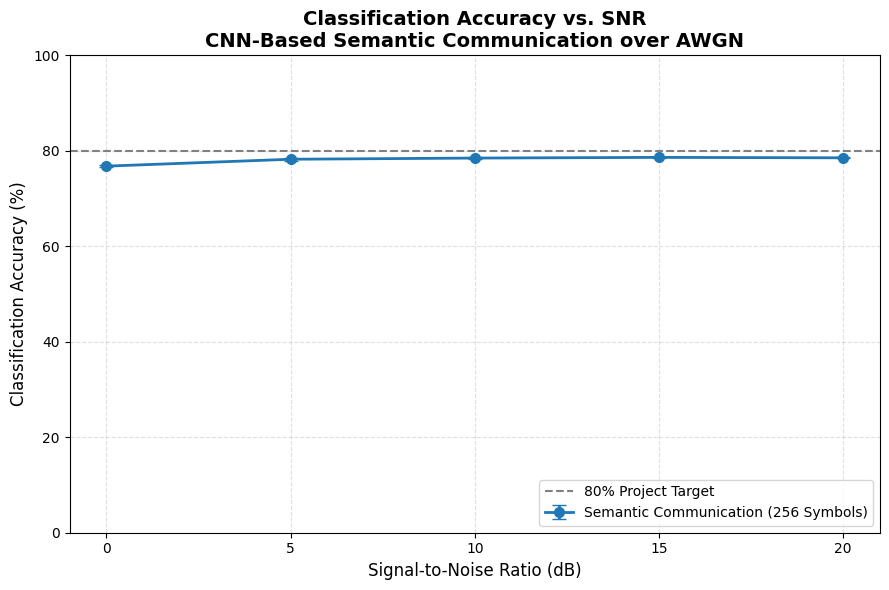

STAGE 1 — EXPERIMENTAL SUMMARY

System Configuration:
Dataset: CIFAR-10
Channel: AWGN
Latent dimension: 256 symbols
Training SNR range: 0–20 dB

Classification Results:
SNR:  0 dB | Accuracy: 76.79% +/- 0.25%
SNR:  5 dB | Accuracy: 78.23% +/- 0.30%
SNR: 10 dB | Accuracy: 78.48% +/- 0.22%
SNR: 15 dB | Accuracy: 78.62% +/- 0.13%
SNR: 20 dB | Accuracy: 78.53% +/- 0.09%

10 dB Performance:
Measured accuracy: 78.48%
Original project target: 80.00%
Result: Target not yet achieved at 10 dB.

Figure saved to: results/accuracy_vs_snr_256.png
Stage 1 experimental visualization completed!


In [12]:

# ============================================================
# ECE 527 Project 5
# Cell 9: Classification Accuracy vs. SNR Visualization
# ============================================================

import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# 1. Prepare Experimental Results
# ------------------------------------------------------------

snr_values = results_df["SNR (dB)"].to_numpy()

mean_accuracies = results_df["Accuracy (%)"].to_numpy()

std_accuracies = results_df[
    "Std Accuracy (%)"
].to_numpy()

# ------------------------------------------------------------
# 2. Create Accuracy vs. SNR Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.errorbar(
    snr_values,
    mean_accuracies,
    yerr=std_accuracies,
    fmt="o-",
    linewidth=2,
    markersize=7,
    capsize=5,
    label="Semantic Communication (256 Symbols)"
)

# ------------------------------------------------------------
# 3. Add Original Project Accuracy Target
# ------------------------------------------------------------

ax.axhline(
    y=80,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="80% Project Target"
)

# ------------------------------------------------------------
# 4. Configure Figure Appearance
# ------------------------------------------------------------

ax.set_title(
    "Classification Accuracy vs. SNR\n"
    "CNN-Based Semantic Communication over AWGN",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Signal-to-Noise Ratio (dB)",
    fontsize=12
)

ax.set_ylabel(
    "Classification Accuracy (%)",
    fontsize=12
)

ax.set_xticks(snr_values)
ax.set_ylim(0, 100)

ax.grid(
    True,
    linestyle="--",
    alpha=0.4
)

ax.legend(loc="lower right")

fig.tight_layout()

# ------------------------------------------------------------
# 5. Save Figure
# ------------------------------------------------------------

os.makedirs("results", exist_ok=True)

figure_path = "results/accuracy_vs_snr_256.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Display Experimental Summary
# ------------------------------------------------------------

print("=" * 55)
print("STAGE 1 — EXPERIMENTAL SUMMARY")
print("=" * 55)

print("\nSystem Configuration:")
print("Dataset: CIFAR-10")
print("Channel: AWGN")
print("Latent dimension: 256 symbols")
print("Training SNR range: 0–20 dB")

print("\nClassification Results:")

for _, row in results_df.iterrows():

    print(
        f"SNR: {int(row['SNR (dB)']):2d} dB | "
        f"Accuracy: {row['Accuracy (%)']:.2f}% "
        f"+/- {row['Std Accuracy (%)']:.2f}%"
    )

# ------------------------------------------------------------
# 7. Evaluate 10 dB Accuracy Target
# ------------------------------------------------------------

accuracy_10db = results_df.loc[
    results_df["SNR (dB)"] == 10,
    "Accuracy (%)"
].iloc[0]

print("\n10 dB Performance:")
print(f"Measured accuracy: {accuracy_10db:.2f}%")
print("Original project target: 80.00%")

if accuracy_10db >= 80.0:
    print("Result: Target achieved at 10 dB.")
else:
    print("Result: Target not yet achieved at 10 dB.")

# ------------------------------------------------------------
# 8. Verify Figure Was Saved
# ------------------------------------------------------------

assert os.path.exists(figure_path)

print("\nFigure saved to:", figure_path)
print("Stage 1 experimental visualization completed!")
